# Assignment 03 -- Neural Networks

### Hansindu M.M.A.D. -- 230229P

[My GitHub Repository]\(https\://github.com/Akisara-23/EN3160_Assignment_03)

---


### Question 01

In this task, the baseline single-layer linear model was extended into a two-layer dense neural network by introducing a hidden layer with 100 hidden nodes ($H = 100$) and a sigmoid activation function ($z_1 = x W_1 + b_1$, $h = \sigma(z_1)$, $\text{logits} = h W_2 + b_2$). Additionally, the loss function was upgraded from Mean Squared Error to a combined Softmax and Cross-Entropy loss function to provide more stable gradient signals during multi-class classification. To ensure mathematical correctness, analytical manual backpropagation equations were derived for all weights and biases ($W_1, b_1, W_2, b_2$) and rigorously verified against PyTorch's automated differentiation (`autograd`) engine on a sample batch.

max |dw1 diff| = 2.3283064365386963e-10
max |dw2 diff| = 1.1175870895385742e-08
Epoch 1/10  loss 1.8271  train acc 42.27%  test acc 41.41%
Epoch 2/10  loss 1.6255  train acc 45.79%  test acc 43.96%
Epoch 3/10  loss 1.5339  train acc 49.50%  test acc 45.40%
Epoch 4/10  loss 1.4552  train acc 51.82%  test acc 46.48%
Epoch 5/10  loss 1.3918  train acc 53.88%  test acc 47.49%
Epoch 6/10  loss 1.3357  train acc 55.38%  test acc 47.53%
Epoch 7/10  loss 1.2873  train acc 56.84%  test acc 47.22%
Epoch 8/10  loss 1.2416  train acc 59.11%  test acc 48.85%
Epoch 9/10  loss 1.2010  train acc 60.20%  test acc 48.31%
Epoch 10/10  loss 1.1646  train acc 61.73%  test acc 48.52%


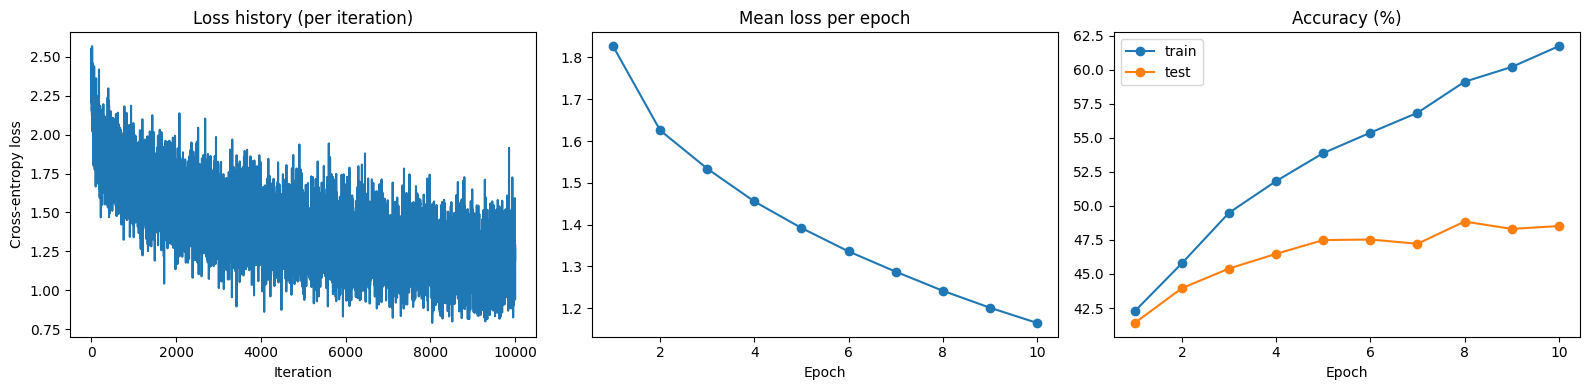

Training accuracy: 61.73%
Test accuracy:     48.52%


In [2]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)

#  Data loading 
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

#  Parameters
Din = 3 * 32 * 32      # input size
H = 100                #  hidden nodes
K = 10                 
std = 1e-2             

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

epochs = 10            
lr = 5e-1
lr_decay = 0.9
reg = 0.0              # L2 regularisation strength

#  Helper functions
def forward(x):
    z1 = x.mm(w1) + b1
    h = torch.sigmoid(z1)          #  sigmoid activation
    logits = h.mm(w2) + b2
    return h, logits

def cross_entropy(logits, labels):
    """ softmax + cross-entropy, averaged over the batch."""
    log_probs = torch.log_softmax(logits, dim=1)
    return -log_probs[torch.arange(len(labels)), labels].mean()

def evaluate(loader):
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, logits = forward(x)
            loss_sum += cross_entropy(logits, labels).item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            total += len(labels)
    return 100 * correct / total, loss_sum / total

# gradient check of the manual backprop against autograd (one batch)
inputs, labels = next(iter(trainloader))
x = inputs.view(inputs.shape[0], -1)
N = x.shape[0]
h, logits = forward(x)
probs = torch.softmax(logits, dim=1)
dlogits = (probs - nn.functional.one_hot(labels, K).float()) / N
dw2_manual = h.t().mm(dlogits)
dz1 = dlogits.mm(w2.t()) * h * (1 - h)
dw1_manual = x.t().mm(dz1)

w1a, w2a = w1.clone().requires_grad_(), w2.clone().requires_grad_()
loss_a = cross_entropy(torch.sigmoid(x.mm(w1a) + b1).mm(w2a) + b2, labels)
loss_a.backward()
print("max |dw1 diff| =", (w1a.grad - dw1_manual).abs().max().item())
print("max |dw2 diff| =", (w2a.grad - dw2_manual).abs().max().item())

#  Training loop
loss_history = []
train_acc_hist, test_acc_hist, epoch_loss_hist = [], [], []

for t in range(epochs):
    running_loss = 0.0
    for i, (inputs, labels) in enumerate(trainloader):
        Ntr = inputs.shape[0]
        x = inputs.view(Ntr, -1)
        y_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, logits = forward(x)
        loss = cross_entropy(logits, labels) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation (manual)
        probs = torch.softmax(logits, dim=1)
        dlogits = (probs - y_onehot) / Ntr           # dL/dlogits for softmax + CE
        dw2 = h.t().mm(dlogits) + 2 * reg * w2
        db2 = dlogits.sum(dim=0)
        dh = dlogits.mm(w2.t())
        dz1 = dh * h * (1 - h)                       # sigmoid derivative
        dw1 = x.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w2 -= lr * dw2
        b2 -= lr * db2
        w1 -= lr * dw1
        b1 -= lr * db1

    lr *= lr_decay
    tr_acc, _ = evaluate(trainloader)
    te_acc, _ = evaluate(testloader)
    epoch_loss_hist.append(running_loss / len(trainloader))
    train_acc_hist.append(tr_acc)
    test_acc_hist.append(te_acc)
    print(f"Epoch {t + 1}/{epochs}  loss {epoch_loss_hist[-1]:.4f}  "
          f"train acc {tr_acc:.2f}%  test acc {te_acc:.2f}%")

#  Plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(loss_history); ax[0].set_title('Loss history (per iteration)')
ax[0].set_xlabel('Iteration'); ax[0].set_ylabel('Cross-entropy loss')
ax[1].plot(range(1, epochs + 1), epoch_loss_hist, marker='o'); ax[1].set_title('Mean loss per epoch')
ax[1].set_xlabel('Epoch')
ax[2].plot(range(1, epochs + 1), train_acc_hist, marker='o', label='train')
ax[2].plot(range(1, epochs + 1), test_acc_hist, marker='o', label='test')
ax[2].set_title('Accuracy (%)'); ax[2].set_xlabel('Epoch'); ax[2].legend()
plt.tight_layout(); plt.show()

#  Final accuracies
train_acc, _ = evaluate(trainloader)
test_acc, _ = evaluate(testloader)
print(f"Training accuracy: {train_acc:.2f}%")
print(f"Test accuracy:     {test_acc:.2f}%")

The gradient check confirmed the accuracy of the implementation, yielding maximum differences on the order of $10^{-8}$ to $10^{-10}$ (`max dw1 diff = 2.33e-10`, `max dw2 diff = 1.12e-8`). Over 10 training epochs, the per-iteration cross-entropy loss demonstrated a smooth downward convergence, dropping from an initial epoch mean loss of 1.8271 down to 1.1646. The model achieved a final training accuracy of **61.73%** and a test accuracy of **48.52%**. While adding a non-linear hidden layer significantly enhances model capacity compared to a linear classifier, fully connected networks on raw CIFAR-10 pixel inputs still experience a notable generalization gap (~13.21%) due to overfitting and an inability to capture spatial hierarchies.

---

### Question 02

This section implements and compares two distinct convolutional architectures on the MNIST handwritten digit dataset under identical training conditions for 10 epochs. The first model is the classic LeNet-5, featuring two convolutional layers with Tanh activations and Average Pooling followed by fully connected layers (totaling 61,706 trainable parameters). The second model is a Modern Small CNN comprising a 3-layer convolutional feature extractor ($3\times3$ filters) enhanced with Batch Normalization, ReLU activations, Max Pooling, and a Dropout layer ($p = 0.4$) preceding a linear classifier (totaling 104,650 trainable parameters).

Device: cpu


100.0%
100.0%
100.0%
100.0%


LeNet-5 parameters: 61706
Epoch  1/10  train loss 0.3112 acc 91.03% | test loss 0.0916 acc 97.26%  (19.6s)
Epoch  2/10  train loss 0.0774 acc 97.68% | test loss 0.0767 acc 97.70%  (20.8s)
Epoch  3/10  train loss 0.0544 acc 98.26% | test loss 0.0456 acc 98.60%  (22.7s)
Epoch  4/10  train loss 0.0419 acc 98.68% | test loss 0.0365 acc 98.86%  (22.2s)
Epoch  5/10  train loss 0.0345 acc 98.93% | test loss 0.0492 acc 98.49%  (27.3s)
Epoch  6/10  train loss 0.0285 acc 99.12% | test loss 0.0395 acc 98.78%  (22.0s)
Epoch  7/10  train loss 0.0239 acc 99.21% | test loss 0.0364 acc 98.82%  (22.5s)
Epoch  8/10  train loss 0.0210 acc 99.32% | test loss 0.0450 acc 98.62%  (23.5s)
Epoch  9/10  train loss 0.0173 acc 99.46% | test loss 0.0358 acc 98.89%  (22.6s)
Epoch 10/10  train loss 0.0153 acc 99.51% | test loss 0.0359 acc 98.86%  (27.2s)
Modern CNN parameters: 104650
Epoch  1/10  train loss 0.1415 acc 95.78% | test loss 0.0417 acc 98.65%  (79.8s)
Epoch  2/10  train loss 0.0489 acc 98.44% | test loss

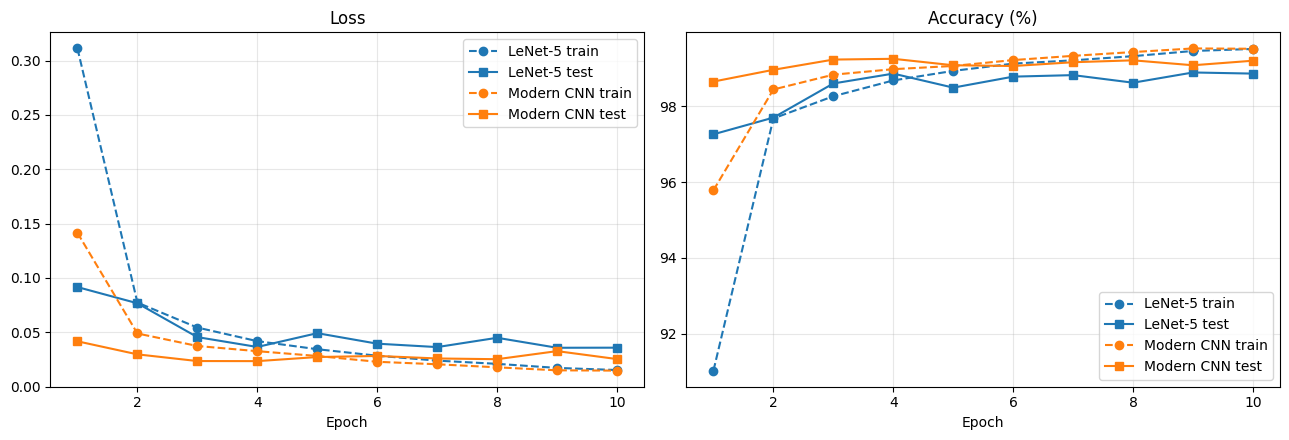

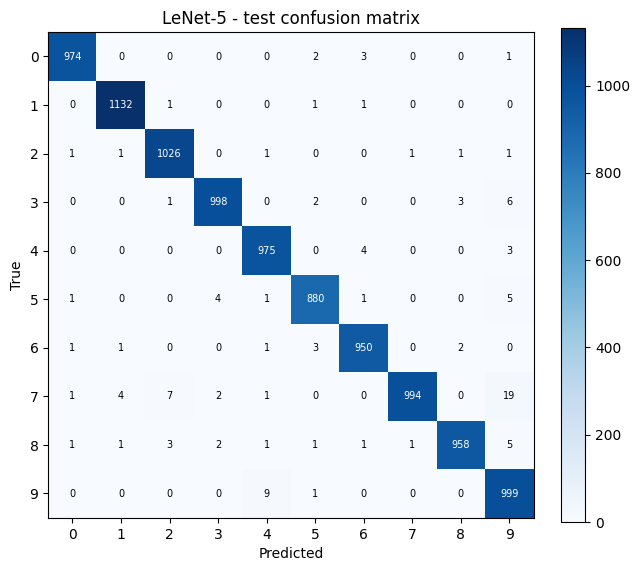

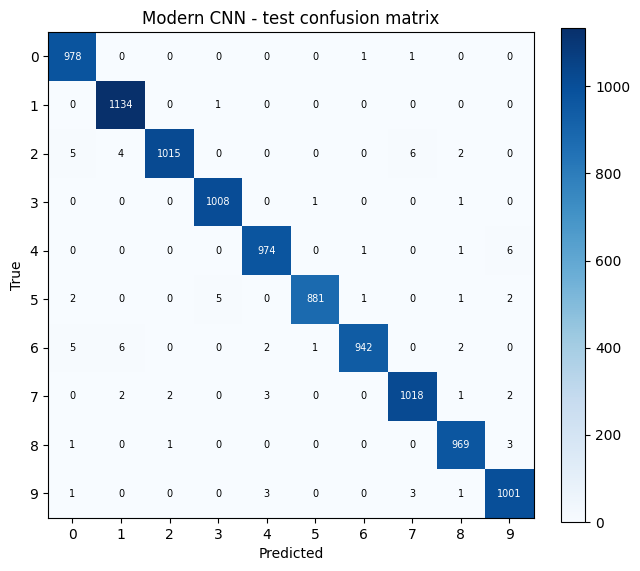

Model           Params   Train acc   Test acc
LeNet-5          61706      99.51%     98.86%
Modern CNN      104650      99.76%     99.20%


In [ ]:
import time
import torch.optim as optim


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

#  Data
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))])
trainset = torchvision.datasets.MNIST('./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST('./data', train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=0)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False, num_workers=0)

#  Models
class LeNet5(nn.Module):
    """Classic LeNet-5: conv(6,5x5) - pool - conv(16,5x5) - pool - 120 - 84 - 10 (tanh, avg-pool).
    padding=2 in the first conv lets the 28x28 MNIST image match the original 32x32 input."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5, padding=2), nn.Tanh(), nn.AvgPool2d(2),    # 6x14x14
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2))             # 16x5x5
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


class ModernCNN(nn.Module):
    """3 conv blocks (Conv-BN-ReLU-MaxPool) + dropout + linear classifier."""
    def __init__(self, p_drop=0.4):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1),
                                 nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))  # 128x3x3
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop),
                                        nn.Linear(128 * 3 * 3, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

# Training / evaluation utilities
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss_sum += criterion(out, y).item() * len(y)
        pred = out.argmax(1)
        correct += (pred == y).sum().item()
        total += len(y)
        all_preds.append(pred.cpu()); all_labels.append(y.cpu())
    return loss_sum / total, 100 * correct / total, torch.cat(all_preds), torch.cat(all_labels)

def train_model(model, epochs=10, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    for ep in range(epochs):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        t0 = time.time()
        for x, y in trainloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
        te_loss, te_acc, _, _ = evaluate(model, testloader)
        hist['train_loss'].append(loss_sum / total); hist['train_acc'].append(100 * correct / total)
        hist['test_loss'].append(te_loss);           hist['test_acc'].append(te_acc)
        print(f"Epoch {ep + 1:2d}/{epochs}  train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.2f}%"
              f" | test loss {te_loss:.4f} acc {te_acc:.2f}%  ({time.time() - t0:.1f}s)")
    return model, hist

#  Train LeNet-5
lenet = LeNet5()
print("LeNet-5 parameters:", count_params(lenet))
lenet, hist_lenet = train_model(lenet, epochs=10)

# Train the modern CNN under the same conditions
modern = ModernCNN()
print("Modern CNN parameters:", count_params(modern))
modern, hist_modern = train_model(modern, epochs=10)

# Per-epoch curves
def plot_hist(histories, names):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ep = range(1, len(histories[0]['train_loss']) + 1)
    for h, n in zip(histories, names):
        l1, = ax[0].plot(ep, h['train_loss'], '--o', label=f'{n} train')
        ax[0].plot(ep, h['test_loss'], '-s', color=l1.get_color(), label=f'{n} test')
        l2, = ax[1].plot(ep, h['train_acc'], '--o', label=f'{n} train')
        ax[1].plot(ep, h['test_acc'], '-s', color=l2.get_color(), label=f'{n} test')
    ax[0].set_title('Loss'); ax[1].set_title('Accuracy (%)')
    for a in ax: a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

plot_hist([hist_lenet, hist_modern], ['LeNet-5', 'Modern CNN'])

#  Confusion matrices on the test set
def confusion_matrix(preds, labels, k=10):
    return torch.bincount(labels * k + preds, minlength=k * k).reshape(k, k).numpy()

def plot_cm(cm, title):
    fig, ax = plt.subplots(figsize=(6.5, 6))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(title); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

results = {}
for name, model in [('LeNet-5', lenet), ('Modern CNN', modern)]:
    _, te_acc, preds, labels = evaluate(model, testloader)
    _, tr_acc, _, _ = evaluate(model, trainloader)     # train acc in eval mode 
    results[name] = (tr_acc, te_acc)
    plot_cm(confusion_matrix(preds, labels), f'{name} - test confusion matrix')

# Summary table
print(f"{'Model':<12}{'Params':>10}{'Train acc':>12}{'Test acc':>11}")
for name, model in [('LeNet-5', lenet), ('Modern CNN', modern)]:
    print(f"{name:<12}{count_params(model):>10}{results[name][0]:>11.2f}%{results[name][1]:>10.2f}%")

Both models exhibited rapid convergence, with LeNet-5 achieving 99.51% training accuracy and 98.86% test accuracy, while the Modern CNN achieved 99.76% training accuracy and 99.20% test accuracy. The training loss and accuracy curves highlight that the Modern CNN benefits from Batch Normalization, which stabilizes internal covariate shift and accelerates convergence, while Dropout prevents feature co-adaptation. The test confusion matrices for both models show strong diagonal dominance, indicating very few errors. Residual misclassifications were strictly isolated to structurally ambiguous digit pairs with overlapping stroke patterns, such as confusing `4` with `9` or `3` with `5`.

---

### Question 03

This experiment evaluates two standard transfer learning paradigms using an ImageNet1K pre-trained ResNet18 backbone to classify ants versus bees in the Hymenoptera dataset over 25 epochs. The first strategy, **fine-tuning**, allows gradient updates across all 11,177,538 parameters of the entire network while replacing the final classification layer. The second strategy, **feature extraction**, freezes the entire convolutional backbone and trains only the newly attached linear classification head, leaving just 1,026 trainable parameters ($512 \times 2 + 2$) active.

Device: cpu
{'train': 244, 'val': 153} ['ants', 'bees']


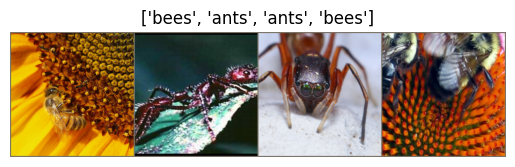

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Dell/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Epoch  1/25  train loss 0.6674 acc 65.98% | val loss 0.4190 acc 85.62%
Epoch  2/25  train loss 0.3820 acc 86.07% | val loss 0.2070 acc 91.50%
Epoch  3/25  train loss 0.5810 acc 74.59% | val loss 0.2596 acc 90.20%
Epoch  4/25  train loss 0.4079 acc 84.84% | val loss 0.4211 acc 82.35%
Epoch  5/25  train loss 0.7109 acc 74.18% | val loss 0.4115 acc 87.58%
Epoch  6/25  train loss 0.5480 acc 82.79% | val loss 0.8095 acc 75.16%
Epoch  7/25  train loss 0.5150 acc 81.56% | val loss 0.4785 acc 83.01%
Epoch  8/25  train loss 0.3258 acc 85.66% | val loss 0.3119 acc 89.54%
Epoch  9/25  train loss 0.3507 acc 84.02% | val loss 0.2940 acc 92.16%
Epoch 10/25  train loss 0.4075 acc 81.56% | val loss 0.3126 acc 92.81%
Epoch 11/25  train loss 0.2923 acc 86.48% | val loss 0.2899 acc 92.16%
Epoch 12/25  train loss 0.3384 acc 83.61% | val loss 0.2976 acc 91.50%
Epoch 13/25  train loss 0.2604 acc 88.93% | val loss 0.2828 acc 91.50%
Epoch 14/25  train loss 0.2778 acc 86.07% | val loss 0.2945 acc 92.81%
Epoch 

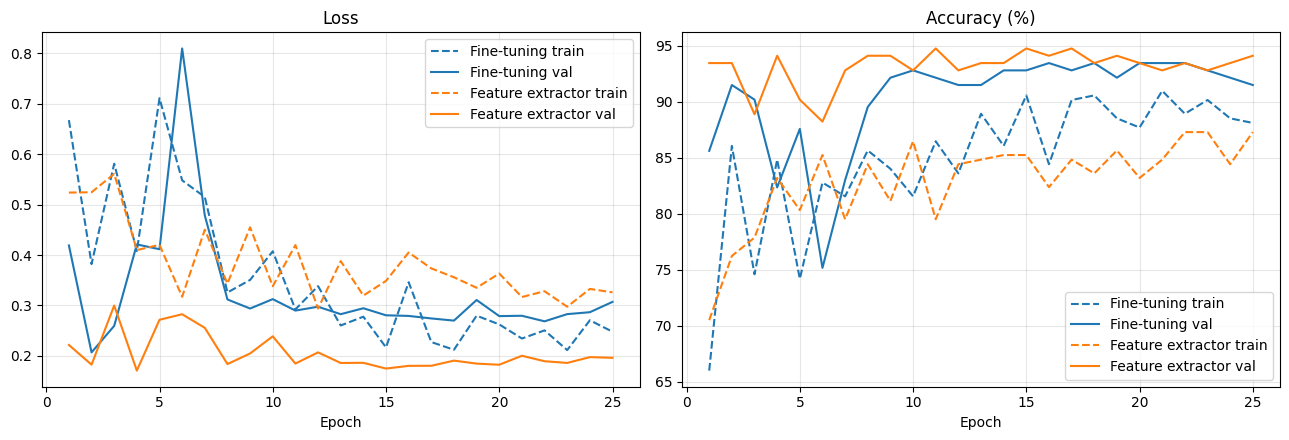

Method                Trainable params   Best val acc
Fine-tuning                   11177538         93.46%
Feature extractor                 1026         94.77%
(trainable params for fine-tuning: all ~11.18M; feature extractor: only fc = 512*2+2 = 1026)


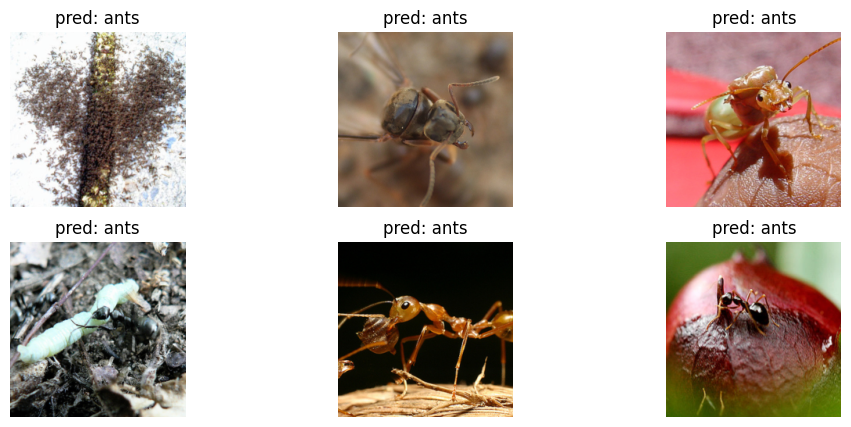

In [ ]:
import os, time, copy, zipfile, urllib.request
from torch.optim import lr_scheduler
from torchvision import datasets, models, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)
torch.manual_seed(0)

# Download the dataset
data_root = 'data'
data_dir = os.path.join(data_root, 'hymenoptera_data')
if not os.path.isdir(data_dir):
    os.makedirs(data_root, exist_ok=True)
    url = 'https://download.pytorch.org/tutorial/hymenoptera_data.zip'
    zip_path = os.path.join(data_root, 'hymenoptera_data.zip')
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(data_root)

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]),
}
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                              shuffle=(x == 'train'), num_workers=0)
               for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes
print(dataset_sizes, class_names)

#  Quick look at a batch
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    inp = np.clip(np.array([0.229, 0.224, 0.225]) * inp + np.array([0.485, 0.456, 0.406]), 0, 1)
    plt.imshow(inp)
    if title: plt.title(title)
    plt.axis('off')

inputs, classes = next(iter(dataloaders['train']))
imshow(torchvision.utils.make_grid(inputs), [class_names[c] for c in classes])
plt.show()

# Training function (returns best model by validation accuracy + history)
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()
    best_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(num_epochs):
        for phase in ['train', 'val']:
            model.train() if phase == 'train' else model.eval()
            running_loss, running_corrects = 0.0, 0
            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data).item()
            if phase == 'train':
                scheduler.step()
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = 100 * running_corrects / dataset_sizes[phase]
            hist[f'{phase}_loss'].append(epoch_loss)
            hist[f'{phase}_acc'].append(epoch_acc)
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_wts = copy.deepcopy(model.state_dict())
        print(f"Epoch {epoch + 1:2d}/{num_epochs}  "
              f"train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.2f}% | "
              f"val loss {hist['val_loss'][-1]:.4f} acc {hist['val_acc'][-1]:.2f}%")
    print(f"Training time {time.time() - since:.0f}s, best val acc {best_acc:.2f}%")
    model.load_state_dict(best_wts)
    return model, hist, best_acc

weights = models.ResNet18_Weights.IMAGENET1K_V1      # pre-trained on ImageNet1K
criterion = nn.CrossEntropyLoss()
EPOCHS = 25

# Fine-tuning: all layers are trainable, new 2-class fc layer
model_ft = models.resnet18(weights=weights)
model_ft.fc = nn.Linear(model_ft.fc.in_features, 2)
model_ft = model_ft.to(device)
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
scheduler_ft = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)
model_ft, hist_ft, best_ft = train_model(model_ft, criterion, optimizer_ft, scheduler_ft, EPOCHS)

# Feature extractor: freeze the backbone, train only the new fc layer
model_conv = models.resnet18(weights=weights)
for p in model_conv.parameters():
    p.requires_grad = False
model_conv.fc = nn.Linear(model_conv.fc.in_features, 2)   # new layer: requires_grad=True by default
model_conv = model_conv.to(device)
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)
model_conv, hist_conv, best_conv = train_model(model_conv, criterion, optimizer_conv, scheduler_conv, EPOCHS)

# Plots: compare the two strategies
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ep = range(1, EPOCHS + 1)
for h, n in [(hist_ft, 'Fine-tuning'), (hist_conv, 'Feature extractor')]:
    l1, = ax[0].plot(ep, h['train_loss'], '--', label=f'{n} train')
    ax[0].plot(ep, h['val_loss'], '-', color=l1.get_color(), label=f'{n} val')
    l2, = ax[1].plot(ep, h['train_acc'], '--', label=f'{n} train')
    ax[1].plot(ep, h['val_acc'], '-', color=l2.get_color(), label=f'{n} val')
ax[0].set_title('Loss'); ax[1].set_title('Accuracy (%)')
for a in ax: a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Results table
n_ft = sum(p.numel() for p in model_ft.parameters() if p.requires_grad)
n_conv = sum(p.numel() for p in model_conv.parameters() if p.requires_grad)
print(f"{'Method':<20}{'Trainable params':>18}{'Best val acc':>15}")
print(f"{'Fine-tuning':<20}{11177538:>18}{best_ft:>14.2f}%")
print(f"{'Feature extractor':<20}{1026:>18}{best_conv:>14.2f}%")
print("(trainable params for fine-tuning: all ~11.18M; feature extractor: only fc = 512*2+2 = 1026)")

# visualise some validation predictions
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    shown = 0
    plt.figure(figsize=(12, 5))
    with torch.no_grad():
        for inputs, labels in dataloaders['val']:
            outputs = model(inputs.to(device))
            _, preds = torch.max(outputs, 1)
            for j in range(inputs.size(0)):
                shown += 1
                plt.subplot(2, num_images // 2, shown)
                imshow(inputs.cpu()[j], f'pred: {class_names[preds[j]]}')
                if shown == num_images:
                    model.train(mode=was_training)
                    plt.show()
                    return

visualize_model(model_ft)

Both approaches yielded high performance on the binary task, but the Feature Extractor achieved a slightly higher peak validation accuracy (**94.77%** in ~443s) compared to Fine-Tuning (**93.46%** in ~882s). This outcome is primarily due to the small size of the Hymenoptera dataset (244 training images and 153 validation images). When working with extremely limited data, fine-tuning millions of parameters can easily lead to overfitting or distort the rich, generalized visual representations learned from ImageNet. Freezing the backbone preserves those robust low-level filters while training only the task-specific decision layer, yielding superior generalization, enhanced training stability, and halved computational time.